# ITT Corredor San Fernando (Yawa) — Comuna 19 — V3 (data centralizada)
**Modelo:** Data Lakehouse. Los eventos de Seguridad/Movilidad/Cohesion se extraen on-the-fly
del repo central `data/01_Dimensiones_ITT_general/` y se recortan al poligono (geofencing).
Educacion, Desarrollo Economico (CCC con PERSONAL_OCUPADO) y NDVI usan los consolidados/rasters
por zona ya validados. **Replica fielmente** las formulas y PESOS del notebook original
`09_itt_san_fernando_5dim.ipynb` (que NO se modifica). V3 debe reproducir la linea base.

In [1]:
# BOOTSTRAP — Colab clona el repo y deja src/ importable. En local no hace nada.
import os, sys, subprocess
from pathlib import Path
REPO_URL = 'https://github.com/j0rg3c45/Itt_repos_cali.git'
IN_COLAB = os.path.exists('/content')
if IN_COLAB:
    REPO = Path('/content/itt_repos_cali')
    if REPO.exists():
        # Pull robusto: Colab ensucia el working tree (outputs) -> reset duro al remoto.
        subprocess.run(['git','-C',str(REPO),'fetch','origin','--quiet'])
        subprocess.run(['git','-C',str(REPO),'reset','--hard','origin/master','--quiet'])
    else:
        subprocess.run(['git','clone','--depth','1',REPO_URL,str(REPO)])
    # dependencias que Colab no trae por defecto
    for _pkg in ['geopandas','folium','rasterio','python-calamine','openpyxl']:
        try:
            __import__(_pkg.replace('-','_'))
        except Exception:
            subprocess.run([sys.executable,'-m','pip','install','-q',_pkg])
else:
    REPO = Path('.')
# src/ importable en cualquier entorno
if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))
print('@@SUB bootstrap | Colab:', IN_COLAB, '| REPO:', REPO)

@@SUB bootstrap | Colab: False | REPO: .


In [2]:
import json, os, sys
from pathlib import Path
import numpy as np, pandas as pd, geopandas as gpd
import warnings; warnings.filterwarnings('ignore')

# Rutas base (Colab: /content/itt_repos_cali ; local: '.')
REPO = Path('/content/itt_repos_cali') if os.path.exists('/content/itt_repos_cali') else Path('.')
if str(REPO) not in sys.path: sys.path.insert(0, str(REPO))
DATA_DIR  = REPO / 'data' / 'itt_Corredor_San_fernando_Yawa'
REPO_GEN  = REPO / 'data' / '01_Dimensiones_ITT_general'
POLY_PATH = DATA_DIR / 'geojson_Corredor_San_fernando.geojson'

# La capa central (~2.3 GB) está en .gitignore y solo existe en LOCAL. Sin ella (Colab),
# el notebook usa el cache liviano versionado data/itt_<zona>/cache_extractor/.
_CACHE_OK = (DATA_DIR / 'cache_extractor' / 'meta.json').exists()
if REPO_GEN.exists():
    _MODO = 'LOCAL: capa central disponible -> se extrae y se regenera el cache'
elif _CACHE_OK:
    _MODO = 'COLAB: sin capa central (normal) -> se usa el cache liviano versionado'
else:
    _MODO = ('[ERROR] sin capa central NI cache. Ejecuta el V3 en LOCAL una vez y '
             'commitea data/itt_<zona>/cache_extractor/')
print('@@SUB setup | REPO=', REPO)
print('  modo:', _MODO)

@@SUB setup | REPO= .
  modo: LOCAL: capa central disponible -> se extrae y se regenera el cache


In [3]:
# CONFIG — pesos y umbrales PROPIOS de la zona (identicos al notebook original inmutable)
ANIOS = [2023, 2024, 2025, 2026]
ANIOS_PARCIALES = [2026]
ZONA_NOMBRE = 'Corredor San Fernando (Yawa) — Comuna 19'
ZONA_SLUG = 'Corredor_San_Fernando'
RINAS_MODO = 'contains'   # 'startswith' (agrupado empieza por RI) o 'exacto' (== RIÑAS)
TIENE_ESPEJO = False   # corredor con espejo (Calle 5/7) vs poligono cerrado
# Raiz de salida opcional (None -> outputs/<Zona>/). Cambiala aqui si quieres otra ubicacion;
# el notebook NO pregunta por consola (asi corre de corrido con 'Run all').
RAIZ_SALIDA = None
PESOS = {"Seguridad": 0.27, "Movilidad": 0.22, "DesSocial": 0.19, "EntornoU": 0.17, "DesEco": 0.15}
REFS = {'homicidios': (0, 15, True), 'hurtos': (800, 2000, True), 'siniestralidad': (80, 240, True), 'lesionados': (70, 210, True), 'mortales': (0, 8, True), 'vif': (30, 90, True), 'rinas': (400, 1100, True), 'spa': (200, 850, True)}
REF_DES = (0, 15); REF_REP = (0, 20)
NOTA_PROVISIONALES = "Zona COMPLETA con data propia: NDVI real, educacion real (IE Liceo Departamental, misma matricula que Roosevelt) integrada en DesSocial, DE con empleo (4591 negocios). Riñas = contains('RI') (amplio, como el calculo del original). V3 = linea base unificada."
def score_ref(valor, rmin, rmax, inverso):
    if rmax == rmin: return 100.0
    raw = np.clip((valor - rmin)/(rmax - rmin)*100, 0, 100)
    return 100 - raw if inverso else raw
def clasificar(v):
    if pd.isna(v): return 'S/D'
    if v < 40: return 'Activacion'
    if v < 60: return 'Consolidacion'
    if v < 80: return 'Transformacion'
    return 'Escala'
print('@@SUB config | pesos suma =', round(sum(PESOS.values()),2))

@@SUB config | pesos suma = 1.0


In [4]:
# EXTRACCION — patron LOCAL/COLAB (cache liviano versionado).
# LOCAL (principal): tiene la capa central (~2.3 GB) -> extrae con el extractor y GUARDA las
#   capas recortadas a la zona en un cache liviano versionado (data/itt_<zona>/cache_extractor/).
# COLAB: NO tiene la capa central (en .gitignore) -> LEE ese cache liviano (viaja con el repo).
# El resto del notebook usa g_hom/g_hur/... igual en ambos entornos.
CACHE_DIR = DATA_DIR / 'cache_extractor'
_CACHE_CAPAS = ['homicidios','hurtos','rinas','spa','vif','siniestros','lesionados','mortales']

def _guardar_cache(capas, arboles_n, cobertura=None):
    CACHE_DIR.mkdir(parents=True, exist_ok=True)
    for nm, gdf in capas.items():
        p = CACHE_DIR / f'{nm}.geojson'
        if gdf is not None and len(gdf):
            out = gdf.copy()
            for c in out.columns:
                if c != 'geometry' and str(out[c].dtype).startswith('datetime'):
                    out[c] = out[c].astype(str)
            out.to_file(p, driver='GeoJSON')
        else:
            # capa vacia: marcador para que Colab sepa que es 0 (no falta de dato)
            gpd.GeoDataFrame({'anio':[]}, geometry=[], crs='EPSG:4326').to_file(p, driver='GeoJSON')
    with open(CACHE_DIR / 'meta.json', 'w', encoding='utf-8') as f:
        json.dump({'zona': ZONA_NOMBRE, 'arboles_n': int(arboles_n),
                   'cobertura_2026': cobertura or {}}, f, ensure_ascii=False, indent=2)

def _leer_cache():
    capas = {}
    for nm in _CACHE_CAPAS:
        p = CACHE_DIR / f'{nm}.geojson'
        g = gpd.read_file(p) if p.exists() else gpd.GeoDataFrame({'anio':[]}, geometry=[], crs='EPSG:4326')
        if 'anio' in g.columns:
            g['anio'] = pd.to_numeric(g['anio'], errors='coerce')
        if '_f' in g.columns:
            g['trimestre'] = pd.to_datetime(g['_f'], errors='coerce').dt.quarter
        capas[nm] = g
    return capas

if REPO_GEN.exists():
    # --- LOCAL: extracción real + escritura de cache ---
    from src.etl_itt_centralizado import ITTZoneExtractor
    ext = ITTZoneExtractor(str(REPO_GEN))
    ext.cargar_poligono(str(POLY_PATH))
    seg = ext.seguridad(rinas_modo=RINAS_MODO); coh = ext.cohesion(); mov = ext.movilidad(); eu_ext = ext.entorno()
    g_hom=seg['homicidios']; g_hur=seg['hurtos']; g_rin=seg['rinas']; g_spa=seg['spa']
    g_vif=coh['vif']; g_sin=mov['siniestros']; g_les=mov['lesionados']; g_mor=mov['mortales']
    _arb_n = len(eu_ext['censo_arboreo']) if eu_ext.get('censo_arboreo') is not None else 0
    _poly_wgs = ext.poly_wgs
    _guardar_cache({'homicidios':g_hom,'hurtos':g_hur,'rinas':g_rin,'spa':g_spa,'vif':g_vif,
                    'siniestros':g_sin,'lesionados':g_les,'mortales':g_mor}, _arb_n,
                   {**seg.get('cobertura_2026', {}), **coh.get('cobertura_2026', {}), **mov.get('cobertura_2026', {})})
    COB_FUENTE = {**seg.get('cobertura_2026', {}), **coh.get('cobertura_2026', {}), **mov.get('cobertura_2026', {})}
    _ORIGEN = 'LOCAL (extractor central) + cache guardado'
else:
    # --- COLAB: lee el cache liviano versionado ---
    if not CACHE_DIR.exists():
        raise FileNotFoundError(f'No hay capa central NI cache en {CACHE_DIR}. '
                                'Ejecuta el V3 en LOCAL una vez para generar el cache y versionarlo.')
    _c = _leer_cache()
    g_hom=_c['homicidios']; g_hur=_c['hurtos']; g_rin=_c['rinas']; g_spa=_c['spa']
    g_vif=_c['vif']; g_sin=_c['siniestros']; g_les=_c['lesionados']; g_mor=_c['mortales']
    with open(CACHE_DIR / 'meta.json', encoding='utf-8') as f: _meta=json.load(f)
    _arb_n = _meta.get('arboles_n', 0)
    COB_FUENTE = _meta.get('cobertura_2026', {})
    _poly_wgs = gpd.read_file(str(POLY_PATH)).to_crs('EPSG:4326')
    _ORIGEN = 'COLAB (cache liviano)'

def _cont(gdf):
    if gdf is None or len(gdf)==0 or 'anio' not in gdf.columns: return {a:0 for a in ANIOS}
    s = gdf.groupby('anio').size(); return {a:int(s.get(a,0)) for a in ANIOS}
print('@@SUB extraccion_central |', _ORIGEN)
print('  Seguridad :', {'homicidios':_cont(g_hom),'hurtos':_cont(g_hur),'rinas':_cont(g_rin),'spa':_cont(g_spa)})
print('  Cohesion  :', {'vif':_cont(g_vif)})
print('  Movilidad :', {'siniestros':_cont(g_sin),'lesionados':_cont(g_les),'mortales':_cont(g_mor)})

[carga] dedup: 21757 duplicados removidos (134623->112866) en 1_Dimension_Seguridad_general


[carga] dedup: 3930 duplicados removidos (600498->596568) en 1_Dimension_Seguridad_general


[carga] dedup: 5530 duplicados removidos (28836->23306) en 2_Dimensión_Cohesion_Social_general


@@SUB extraccion_central | LOCAL (extractor central) + cache guardado
  Seguridad : {'homicidios': {2023: 9, 2024: 8, 2025: 8, 2026: 3}, 'hurtos': {2023: 1629, 2024: 1392, 2025: 1245, 2026: 747}, 'rinas': {2023: 616, 2024: 563, 2025: 925, 2026: 584}, 'spa': {2023: 581, 2024: 356, 2025: 696, 2026: 223}}
  Cohesion  : {'vif': {2023: 57, 2024: 52, 2025: 68, 2026: 37}}
  Movilidad : {'siniestros': {2023: 195, 2024: 167, 2025: 142, 2026: 50}, 'lesionados': {2023: 168, 2024: 150, 2025: 123, 2026: 46}, 'mortales': {2023: 4, 2024: 3, 2025: 5, 2026: 1}}


In [5]:
# Construye base (anual) y corr_trim (trimestral) desde los GeoDataFrames extraidos.
def _anual(gdf):
    if gdf is None or len(gdf)==0 or 'anio' not in gdf.columns:
        return {a:0 for a in ANIOS}
    s = gdf.groupby('anio').size()
    return {a:int(s.get(a,0)) for a in ANIOS}
def _with_trim(gdf):
    # El extractor añade 'anio' y '_f' (fecha parseada) pero NO 'trimestre'.
    # Se deriva aquí desde '_f' para la lógica trimestral/cobertura 2026.
    if gdf is None or len(gdf)==0: return gdf
    g = gdf
    if 'trimestre' not in g.columns and '_f' in g.columns:
        g = g.copy(); g['trimestre'] = pd.to_datetime(g['_f'], errors='coerce').dt.quarter
    return g
def _trim(gdf):
    idx = pd.MultiIndex.from_product([ANIOS,[1,2,3,4]], names=['anio','trimestre'])
    g = _with_trim(gdf)
    if g is None or len(g)==0 or 'trimestre' not in g.columns:
        return pd.Series(0, index=idx)
    return g.groupby(['anio','trimestre']).size().reindex(idx, fill_value=0)

# g_hom/g_hur/... ya vienen de la celda de extraccion (LOCAL extractor o COLAB cache).
base = pd.DataFrame({'año': ANIOS})
_map_anual = {'homicidios':g_hom,'hurtos':g_hur,'siniestralidad':g_sin,'lesionados':g_les,
              'mortales':g_mor,'vif':g_vif,'rinas':g_rin,'spa':g_spa}
for k,g in _map_anual.items():
    ca = _anual(g); base[k] = [ca[a] for a in ANIOS]

idx_t = pd.MultiIndex.from_product([ANIOS,[1,2,3,4]], names=['año','trimestre'])
corr_trim = pd.DataFrame(index=idx_t).reset_index()
_trim_inds = ['homicidios','hurtos','siniestralidad','lesionados','mortales','vif','rinas']
for k,g in [('homicidios',g_hom),('hurtos',g_hur),('siniestralidad',g_sin),
            ('lesionados',g_les),('mortales',g_mor),('vif',g_vif),('rinas',g_rin)]:
    ser = _trim(g).reset_index(); ser.columns=['año','trimestre',k]
    corr_trim = corr_trim.merge(ser, on=['año','trimestre'], how='left').fillna({k:0})

# ── NULLIFY 2026 por cobertura parcial (criterio conservador, igual al original) ──
# 2026 es parcial: comparar acumulados parciales contra umbrales de año completo
# infla los indicadores inversos. Se detecta el ultimo trimestre con dato por
# indicador y se anula (NaN) lo no cubierto; el conteo anual 2026 se recomputa como
# la suma de los trimestres cubiertos. Siniestralidad/lesionados/mortales comparten
# la cobertura de siniestros. 2026 NO se rotula "Parcial" en graficas/Excel.
def _qmax_2026(gdf):
    g = _with_trim(gdf)
    if g is None or len(g)==0 or 'trimestre' not in g.columns or 'anio' not in g.columns: return 0
    s = g[g['anio']==2026]
    return int(s['trimestre'].max()) if len(s) and s['trimestre'].notna().any() else 0
# Cobertura 2026 = ultimo trimestre con dato en la FUENTE COMPLETA (ciudad), no en la zona:
# 0 eventos en la zona no significa que falte el dato. Fallback a la zona si no hay info.
_cf = COB_FUENTE or {}
_cob = {'homicidios':_cf.get('homicidios', _qmax_2026(g_hom)),
        'hurtos':_cf.get('hurtos', _qmax_2026(g_hur)),
        'vif':_cf.get('vif', _qmax_2026(g_vif)),
        'rinas':_cf.get('comparendos', _qmax_2026(g_rin)),
        'siniestralidad':_cf.get('siniestros', _qmax_2026(g_sin)),
        'lesionados':_cf.get('siniestros', _qmax_2026(g_sin)),
        'mortales':_cf.get('siniestros', _qmax_2026(g_sin))}
for k,qmax in _cob.items():
    corr_trim.loc[(corr_trim['año']==2026) & (corr_trim['trimestre']>qmax), k] = np.nan
    # recomputa conteo anual 2026 = suma de trimestres cubiertos
    cob26 = corr_trim[(corr_trim['año']==2026)][k].sum(min_count=1)
    base.loc[base['año']==2026, k] = cob26 if pd.notna(cob26) else 0
# SPA: mismo criterio de cobertura 2026 (no esta en corr_trim; se recorta directo)
_q_spa = _cf.get('comparendos', _qmax_2026(g_spa)); _cob['spa'] = _q_spa
_g_spa_t = _with_trim(g_spa)
if _g_spa_t is not None and len(_g_spa_t) and 'trimestre' in _g_spa_t.columns:
    _spa26 = _g_spa_t[(_g_spa_t['anio']==2026) & (_g_spa_t['trimestre']<=_q_spa)]
    base.loc[base['año']==2026, 'spa'] = int(len(_spa26))
corr_trim['periodo'] = corr_trim['año'].astype(str)+'-Q'+corr_trim['trimestre'].astype(str)
print('@@SUB base | cobertura 2026 (ult. trimestre con dato):',
      {k:f'Q{v}' for k,v in _cob.items()})
print(base.to_string(index=False))

@@SUB base | cobertura 2026 (ult. trimestre con dato): {'homicidios': 'Q3', 'hurtos': 'Q3', 'vif': 'Q3', 'rinas': 'Q3', 'siniestralidad': 'Q2', 'lesionados': 'Q2', 'mortales': 'Q2', 'spa': 'Q3'}
 año  homicidios  hurtos  siniestralidad  lesionados  mortales  vif  rinas  spa
2023           9    1629             195         168         4   57    616  581
2024           8    1392             167         150         3   52    563  356
2025           8    1245             142         123         5   68    925  696
2026           3     747              50          46         1   37    584  223


In [6]:
# SCORES (mismas formulas y REFS del original).
# ANUALIZACION 2026 SOLO PARA SCORES: 2026 es parcial (la capa central tiene cobertura
# distinta por fuente: delitos/VIF/riñas/SPA hasta Q1; siniestros hasta Q2). Comparar un
# acumulado parcial contra umbrales de AÑO COMPLETO infla los indicadores inversos, asi que
# para el SCORE se proyecta el conteo a año completo: valor * 4 / trimestres_cubiertos.
# REGLA: 'base' conserva los CONTEOS REALES observados (lo que va a Excel/tablas/graficas).
# La anualizacion vive en una copia 'base_sc' que SOLO alimenta score_ref. Nada anualizado
# se exporta. _cob (trimestres cubiertos por indicador) viene de la celda de extraccion/base.
_IND_SCORE = ['homicidios','hurtos','siniestralidad','lesionados','mortales','vif','rinas','spa']
base_sc = base.copy()
# las columnas de conteo son int; la anualizacion produce floats -> castear en la copia
for ind in _IND_SCORE:
    if ind in base_sc.columns:
        base_sc[ind] = base_sc[ind].astype(float)
_factor = {}
for ind in _IND_SCORE:
    q = _cob.get(ind, 0)
    f = (4.0/q) if (q and q < 4) else 1.0     # Q1->x4, Q2->x2, Q3->x1.33, Q4/0->x1
    _factor[ind] = round(f, 3)
    if ind in base_sc.columns:
        base_sc.loc[base_sc['año']==2026, ind] = base_sc.loc[base_sc['año']==2026, ind] * f
# score_ref se calcula sobre base_sc (anualizada en 2026); los conteos reales quedan en base
for ind,(rmin,rmax,inv) in REFS.items():
    if ind in base_sc.columns:
        base[f'score_{ind}'] = base_sc[ind].apply(lambda v: score_ref(v,rmin,rmax,inv))
base['score_seguridad'] = (base['score_homicidios'] + base['score_hurtos'])/2
base['score_movilidad'] = (base['score_siniestralidad'] + base['score_lesionados'] + base['score_mortales'])/3
base['score_cohesion']  = (base['score_vif'] + base['score_rinas'] + base['score_spa'])/3
# placeholders (sobreescritos por EU/ED/DE)
base['score_entorno_u'] = np.nan
base['score_educ_des']  = np.nan
base['score_des_eco']   = np.nan
base['score_des_social']= (base['score_cohesion'] + base['score_educ_des'])/2
def _itt_row(row):
    dims = {'Seguridad':row.get('score_seguridad'),'Movilidad':row.get('score_movilidad'),
            'DesSocial':row.get('score_des_social'),'EntornoU':row.get('score_entorno_u'),
            'DesEco':row.get('score_des_eco')}
    tot = sum(PESOS[k] for k,v in dims.items() if not pd.isna(v))
    if tot==0: return np.nan
    return sum(PESOS[k]*v for k,v in dims.items() if not pd.isna(v))/tot
print('@@SUB scores_seg_mov_coh')
print('  factores anualizacion 2026 (solo para score):', _factor)
print(base[['año','score_seguridad','score_movilidad','score_cohesion']].round(2).to_string(index=False))

@@SUB scores_seg_mov_coh
  factores anualizacion 2026 (solo para score): {'homicidios': 1.333, 'hurtos': 1.333, 'siniestralidad': 2.0, 'lesionados': 2.0, 'mortales': 2.0, 'vif': 1.333, 'rinas': 1.333, 'spa': 1.333}
 año  score_seguridad  score_movilidad  score_cohesion
2023            35.46            36.04           55.18
2024            48.67            50.33           72.02
2025            54.79            53.63           28.45
2026            78.50            82.26           66.24


In [7]:
# ENTORNO URBANO — NDVI (rasters locales de la zona, versionados) + arboles.
# ARBOLES_N viene de la celda de extraccion (_arb_n): LOCAL del extractor, COLAB del cache/meta.
import importlib.util
NDVI_DIR = DATA_DIR / '5_Dimension_Entorno_Urbano/NDVI_Corredor_San_fernando_Yawa'
NDVI_POR_ANIO = {"2023": "Corredor_San_fernando_Yawa_ndvi_2023.tif", "2024": "Corredor_San_fernando_Yawa_ndvi_2024.tif", "2025": "Corredor_San_fernando_Yawa_ndvi_2025.tif", "2026": "Corredor_San_fernando_Yawa_ndvi_2026.tif"}
NDVI_UMBRAL = 0.20
ARBOLES_N = _arb_n
ndvi_stats = {}; AREA_HA = None
if importlib.util.find_spec('rasterio'):
    import rasterio
    for a in ANIOS:
        _spec = NDVI_POR_ANIO.get(str(a), NDVI_POR_ANIO.get(a))
        # _spec puede ser un nombre (zona de 1 raster) o una LISTA de nombres (multi-tramo).
        _files = _spec if isinstance(_spec, list) else ([_spec] if _spec else [])
        _tifs = [NDVI_DIR / fn for fn in _files if (NDVI_DIR / fn).exists()]
        if not _tifs:
            ndvi_stats[a] = {'pct_verde':np.nan}; continue
        _tot_a = 0; _verde_a = 0; _area_a = 0.0
        for tif in _tifs:  # acumula pixeles de todos los tramos del año (promedio ponderado por area)
            with rasterio.open(tif) as src:
                d = src.read(1).astype(float)
                if src.nodata is not None: d[d==src.nodata]=np.nan
                px = abs(src.transform.a)*111320*np.cos(np.radians(3.44)) * abs(src.transform.e)*110540
                _tot_a += int(np.sum(~np.isnan(d))); _verde_a += int(np.sum(d>=NDVI_UMBRAL))
                _area_a += int(np.sum(~np.isnan(d)))*px/10000
        ndvi_stats[a] = {'pct_verde': round(_verde_a/_tot_a*100,1) if _tot_a else np.nan}
        if AREA_HA is None: AREA_HA = round(_area_a,2)
dens = round(ARBOLES_N/AREA_HA,1) if AREA_HA else np.nan
score_arb = round(score_ref(dens,0,50,False),1) if not np.isnan(dens) else np.nan
for a in ANIOS:
    pct = ndvi_stats.get(a,{}).get('pct_verde',np.nan)
    scv = score_ref(pct,0,30,False) if not np.isnan(pct) else np.nan
    sceu = round((scv+score_arb)/2,1) if not np.isnan(scv) else score_arb
    base.loc[base['año']==a,'score_entorno_u'] = sceu
print('@@SUB entorno | arboles(zona)=', ARBOLES_N, '| dens=', dens, '| score_arb=', score_arb)
print(base[['año','score_entorno_u']].round(1).to_string(index=False))

@@SUB entorno | arboles(zona)= 14567 | dens= 54.1 | score_arb= 100.0
 año  score_entorno_u
2023            100.0
2024            100.0
2025            100.0
2026            100.0


In [8]:
# EDUCACION — consolidado por zona (lista de DANES). Si la zona NO tiene consolidado
# (p.ej. Ciudad Paraiso: educacion fuera de alcance / otro repo), score_educ_des = NaN
# y DesSocial = SOLO cohesion (el _itt_row renormaliza). REF_DES/REF_REP de la config.
_EDUC_REL = '6_Dimension_Educacion/educacion_SF_2023_2026_consolidado.json'
_EDUC_JSON = (DATA_DIR / _EDUC_REL) if _EDUC_REL else None
mat = rep = des = {}
if _EDUC_JSON is not None and _EDUC_JSON.exists():
    with open(_EDUC_JSON, encoding='utf-8') as f: _ec = json.load(f)
    mat = {int(k):v for k,v in _ec['matricula'].items()}
    rep = {int(k):v for k,v in _ec['repitentes'].items()}
    des = {int(k):v for k,v in _ec['desertores'].items()}
else:
    print('  [NOTA] sin consolidado de educacion -> score_educ_des = NaN; DesSocial = solo Cohesion.')
for a in ANIOS:
    m=mat.get(a); r=rep.get(a); d=des.get(a)
    tdes = round(d/m*100,2) if (d is not None and m) else np.nan
    trep = round(r/m*100,2) if (r is not None and m) else np.nan
    sd = score_ref(tdes,*REF_DES,True) if not pd.isna(tdes) else np.nan
    sr = score_ref(trep,*REF_REP,True) if not pd.isna(trep) else np.nan
    disp=[s for s in [sd,sr] if not pd.isna(s)]
    sc = round(sum(disp)/len(disp),1) if disp else np.nan
    if a != 2026:
        base.loc[base['año']==a,'score_educ_des'] = sc
# carry-forward 2026 = ultimo año real
_last = base.loc[base['año'].isin([2023,2024,2025]),'score_educ_des'].dropna()
if not _last.empty:
    base.loc[base['año']==2026,'score_educ_des'] = float(_last.iloc[-1])
# DesSocial = media de componentes DISPONIBLES (cohesion [+ educacion si la zona la tiene]).
# nanmean -> si no hay educacion, DesSocial = solo cohesion (no NaN). Evita que DesSocial
# desaparezca del ITT en zonas sin consolidado de educacion (Ciudad Paraiso, Av. Ciudad de Cali).
base['score_des_social'] = base[['score_cohesion','score_educ_des']].apply(
    lambda r: np.nanmean([r['score_cohesion'], r['score_educ_des']]), axis=1)
print('@@SUB educacion')
print(base[['año','score_educ_des','score_des_social']].round(1).to_string(index=False))

@@SUB educacion
 año  score_educ_des  score_des_social
2023            72.0              63.6
2024            80.4              76.2
2025            79.8              54.1
2026            79.8              73.0


In [9]:
# DESARROLLO ECONOMICO — consolidado CCC por zona (empleo = PERSONAL_OCUPADO).
_DE_JSON = DATA_DIR / '4_Dimension_Desarrollo_Economico/registro_mercantil_SF_2023_2026_consolidado.json'
with open(_DE_JSON, encoding='utf-8') as f: _de = json.load(f)
df_de = pd.DataFrame(_de['registros'])
df_de['fecha_mat']=pd.to_datetime(df_de['fechaMatricula'],errors='coerce')
df_de['fecha_cancel']=pd.to_datetime(df_de['fechaCancelacion'],errors='coerce')
df_de['anio_mat']=df_de['fecha_mat'].dt.year
df_de['ingresos']=pd.to_numeric(df_de['ingresosOrdinarios'],errors='coerce')
df_de['ingresos_limpio']=df_de['ingresos'].where(df_de['ingresos']>0,np.nan)
# Empleo (PERSONAL_OCUPADO) solo si el consolidado de la zona lo trae; si no, el score DE
# usa los componentes disponibles (establecimientos + ingresos), igual que el ITT con dims NaN.
_HAY_EMPLEO = 'empleo' in df_de.columns
df_de['empleo']=pd.to_numeric(df_de['empleo'],errors='coerce') if _HAY_EMPLEO else np.nan
def _stock_mask(df,X):
    return (df['anio_mat']<=X) & (df['fecha_cancel'].isna() | (df['fecha_cancel'].dt.year>X))
rows=[]
for a in ANIOS:
    sub=df_de[_stock_mask(df_de,a)]
    ing=float(sub.loc[sub['ingresos_limpio']>0,'ingresos_limpio'].sum())
    emp=float(sub.loc[sub['empleo']>=0,'empleo'].sum()) if _HAY_EMPLEO else np.nan
    rows.append({'año':a,'est':float(len(sub)),'emp':emp,'ing':ing,'ing_log':float(np.log1p(ing))})
dfs=pd.DataFrame(rows)
REF_EST=(0,int(dfs['est'].max())); REF_ING=(float(dfs['ing_log'].min()),float(dfs['ing_log'].max()))
_empm=float(dfs['emp'].max()) if _HAY_EMPLEO and dfs['emp'].notna().any() else 0.0
REF_PERS=(0,_empm*1.15 if _empm>0 else 1)
for _,r in dfs.iterrows():
    sn=score_ref(r['est'],*REF_EST,False)
    sp=score_ref(r['emp'],*REF_PERS,False) if (_HAY_EMPLEO and not pd.isna(r['emp'])) else np.nan
    si=score_ref(r['ing_log'],*REF_ING,False)
    sde=float(np.mean([x for x in [sn,sp,si] if not pd.isna(x)]))
    base.loc[base['año']==int(r['año']),'score_des_eco']=sde
base['ITT']=base.apply(_itt_row,axis=1)
base['nivel']=base['ITT'].apply(clasificar)
print('@@SUB desarrollo_economico | empleo disponible:', _HAY_EMPLEO)
print(dfs[['año','est','emp']].to_string(index=False))
print(base[['año','score_des_eco','ITT','nivel']].round(2).to_string(index=False))

@@SUB desarrollo_economico | empleo disponible: True
 año    est     emp
2023 3517.0 33550.0
2024 3812.0 34846.0
2025 3994.0 35074.0
2026 4126.0 34969.0
 año  score_des_eco   ITT          nivel
2023          56.14 55.01  Consolidacion
2024          71.74 66.45 Transformacion
2025          94.45 68.04 Transformacion
2026          95.57 84.50         Escala


In [10]:
# VALIDACION — comparar ITT del V3 contra la linea base del Excel del notebook original.
_XLS = REPO / 'outputs/itt_corredor_san_fernando/ITT_Corredor_San_Fernando_Consolidado.xlsx'
print('@@SUB validacion')
if _XLS.exists():
    import openpyxl
    wb=openpyxl.load_workbook(_XLS, data_only=True); ws=wb['ITT_Resumen']
    base_orig={}
    rows=list(ws.iter_rows(values_only=True)); hdr=rows[0]
    for r in rows[1:]:
        d=dict(zip(hdr,r)); base_orig[int(d['año'])]={'ITT':d['ITT'],'seg':d['score_seguridad'],
            'mov':d['score_movilidad'],'ds':d['score_des_social'],'eu':d['score_entorno_u'],'de':d['score_des_eco']}
    print('  año | ITT_v3 | ITT_orig | dif    (orig = Excel viejo; puede usar valores PROVISIONALES)')
    for a in ANIOS:
        v3=float(base.loc[base['año']==a,'ITT'].iloc[0]); o=base_orig.get(a,{}).get('ITT')
        dif = round(v3-o,2) if o is not None else None
        print(f'  {a} | {v3:.2f} | {o} | {dif}')
else:
    print('  (no hay Excel original para comparar)')
if NOTA_PROVISIONALES:
    print('  NOTA (provisionales del original):', NOTA_PROVISIONALES)
print('  V3 = linea base UNIFICADA: una metodologia para todas las zonas; validar consistencia')
print('  interna (extractor==tablas==graficas==Excel==GeoJSON), no igualdad con el Excel viejo.')
print()
print(base[['año','score_seguridad','score_movilidad','score_des_social','score_entorno_u','score_des_eco','ITT','nivel']].round(2).to_string(index=False))

@@SUB validacion


  año | ITT_v3 | ITT_orig | dif    (orig = Excel viejo; puede usar valores PROVISIONALES)
  2023 | 55.01 | 47.99 | 7.02
  2024 | 66.45 | 58.16 | 8.29
  2025 | 68.04 | 55.12 | 12.92
  2026 | 84.50 | 79.21 | 5.29
  NOTA (provisionales del original): Zona COMPLETA con data propia: NDVI real, educacion real (IE Liceo Departamental, misma matricula que Roosevelt) integrada en DesSocial, DE con empleo (4591 negocios). Riñas = contains('RI') (amplio, como el calculo del original). V3 = linea base unificada.
  V3 = linea base UNIFICADA: una metodologia para todas las zonas; validar consistencia
  interna (extractor==tablas==graficas==Excel==GeoJSON), no igualdad con el Excel viejo.

 año  score_seguridad  score_movilidad  score_des_social  score_entorno_u  score_des_eco   ITT          nivel
2023            35.46            36.04             63.59            100.0          56.14 55.01  Consolidacion
2024            48.67            50.33             76.21            100.0          71.74 66.45 T

## Visualización y salidas
Replica la paleta Okabe-Ito, las gráficas, el mapa (tiles Google) y los exports del notebook
original. **Regla:** las cifras de gráficas/Excel/GeoJSON usan los CONTEOS REALES observados
(`base`), nunca los anualizados (que solo alimentan el score). 2026 no lleva rótulo 'Parcial'.

In [11]:
# ESTILO — ESTANDAR VISUAL ITT: color canonico por dimension/evento + estilo editorial.
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
DPI = 300
# Base Okabe-Ito (accesibilidad; se usa en transversales/radar).
OKI_AZUL='#0072B2'; OKI_NARANJA='#E69F00'; OKI_VERDE='#009E73'; OKI_AMARILLO='#F0E442'
OKI_AZUL_C='#56B4E9'; OKI_BERMELL='#D55E00'; OKI_MORADO='#CC79A7'; OKI_GRIS='#333333'
# Paleta ITT por EVENTO/DIMENSION (estandar oficial, mapeo semantico).
ITT = {
    # D1 Seguridad
    'homicidios':'#8B0000','hurtos':'#6A1B9A','rinas':'#E65100','spa':'#4A148C',
    # D2 Cohesion
    'vif':'#C2185B','vbg':'#AD1457',
    # D3 Movilidad
    'siniestralidad':'#C0392B','lesionados':'#D9534F','mortales':'#455A64',
    # D4 Desarrollo Economico
    'establecimientos':'#1565C0','empleo':'#0D47A1','ingresos':'#1976D2','de':'#0D47A1',
    # D5 Entorno
    'caminable':'#2A9C8A','nodos':'#D9534F','arboreo':'#2E7D32','ndvi_cmap':'YlGn',
    'poligono_borde':'#1B4F8A',
    # transversal
    'itt':'#1B2631','educacion':'#2A9C8A',
}
# Color por DIMENSION (para series agregadas por dimension en transversales).
DIM_COLOR = {'Seguridad':'#6A1B9A','Movilidad':'#C0392B','DesSocial':'#C2185B',
             'EntornoU':'#2E7D32','DesEco':'#0D47A1'}
BG='#FFFFFF'   # estilo editorial: fondo blanco limpio
GRID='#E0E0E0'
NIVEL_COLORS={'Activacion':'#C0392B','Consolidacion':'#E65100',
              'Transformacion':'#2A9C8A','Escala':'#1565C0'}
plt.rcParams.update({'figure.facecolor':BG,'axes.facecolor':BG,'font.family':'DejaVu Sans',
    'axes.spines.top':False,'axes.spines.right':False,'axes.grid':True,
    'grid.color':GRID,'grid.alpha':0.3,'axes.titleweight':'bold','savefig.facecolor':BG})

# ── ESTRUCTURA DE SALIDAS ESTANDAR (obligatoria) — prefijo mapa_analitico_ ────
# outputs/mapa_analitico_<Zona>/mapa_analitico_<Zona>_consolidado.xlsx
#   + outputs/mapa_analitico_<Zona>/imagenes/<figuras> + mapa_analitico_<Zona>.html
#   + outputs/mapa_analitico_<Zona>/geojson_capas/ + mapa_analitico_manifest_<Zona>.json
# Todas las figuras/mapas van SIEMPRE en la subcarpeta 'imagenes/'. Nada suelto en
# notebooks/ ni en la raiz. La subestructura mapa_analitico_<Zona>/imagenes/ es fija.
# ZONA_SLUG viene de la celda de config (v3_config)
OUT_DIR_NAME = f'mapa_analitico_{ZONA_SLUG}'   # carpeta y prefijo de entregables
OUT_ZONA = REPO / 'outputs' / OUT_DIR_NAME
OUT_IMG  = OUT_ZONA / 'imagenes'
OUT_IMG.mkdir(parents=True, exist_ok=True)
_OUT_IMG = OUT_IMG   # alias para las celdas de graficas/mapa
print('@@SUB estilo | estandar visual ITT (color por dimension/evento) | dpi', DPI, '| zona:', ZONA_SLUG)
print('  raiz zona :', OUT_ZONA)
print('  imagenes  :', OUT_IMG)

@@SUB estilo | estandar visual ITT (color por dimension/evento) | dpi 300 | zona: Corredor_San_Fernando
  raiz zona : outputs\mapa_analitico_Corredor_San_Fernando
  imagenes  : outputs\mapa_analitico_Corredor_San_Fernando\imagenes


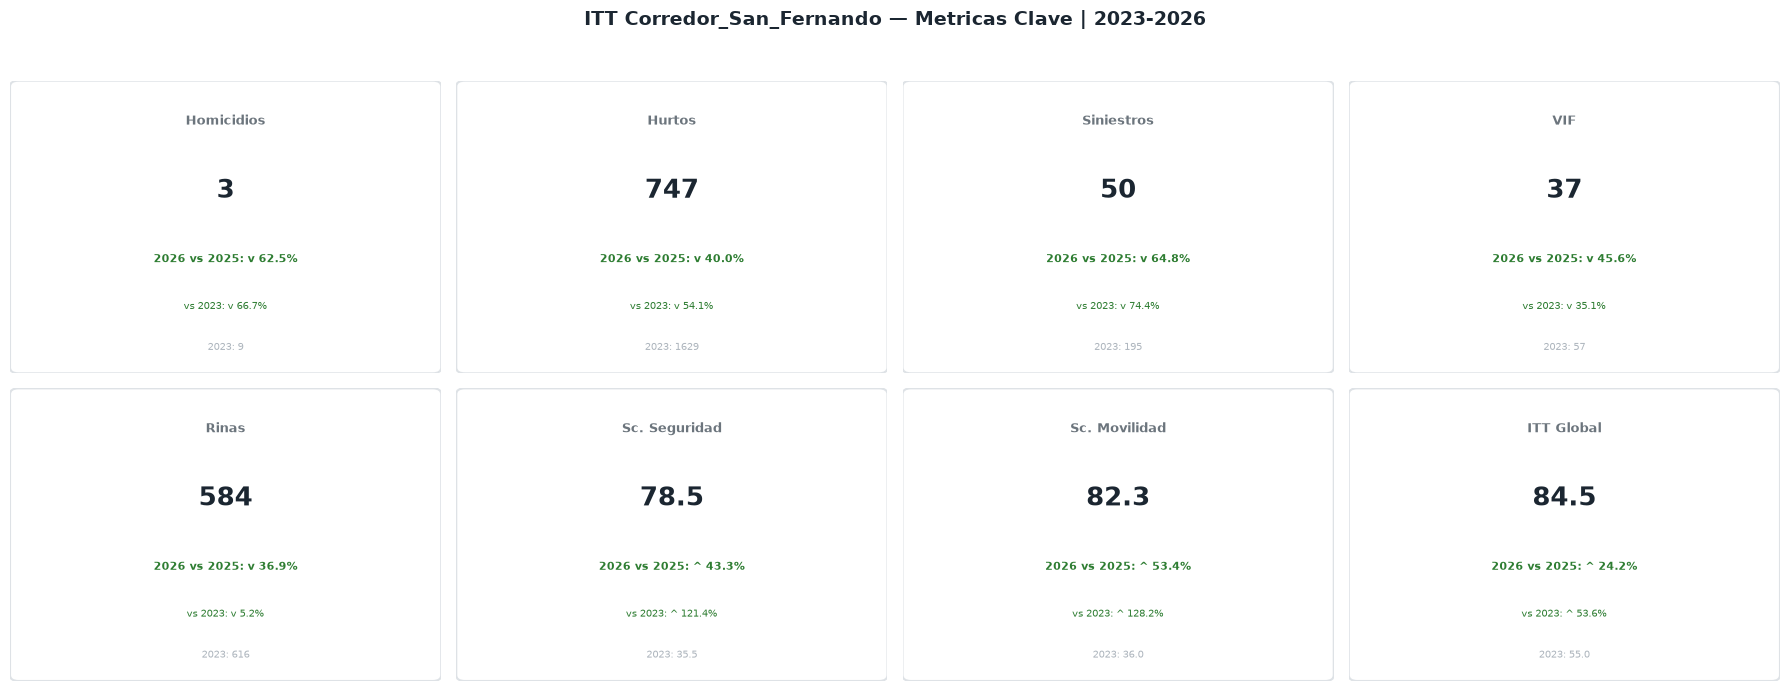

@@SUB cards | ITT 2026 = 84.5 | conteos reales (no anualizados)


In [12]:
# CARDS — métricas clave (conteos REALES observados de base). 2026 sin rótulo 'Parcial'.
def safe_pct(new, old):
    return 0.0 if old==0 else (new-old)/old*100
def arrow(pct, inv=True):
    if abs(pct)<1: return 'Sin cambio','gray'
    if inv: return (f'v {abs(pct):.1f}%','#2E7D32') if pct<0 else (f'^ {abs(pct):.1f}%','#C62828')
    return (f'^ {abs(pct):.1f}%','#2E7D32') if pct>0 else (f'v {abs(pct):.1f}%','#C62828')
d_ini=base[base['año']==2023].iloc[0]; d_ant=base[base['año']==2025].iloc[0]; d_ult=base[base['año']==2026].iloc[0]
cards=[('Homicidios',int(d_ini['homicidios']),int(d_ant['homicidios']),int(d_ult['homicidios']),True),
       ('Hurtos',int(d_ini['hurtos']),int(d_ant['hurtos']),int(d_ult['hurtos']),True),
       ('Siniestros',int(d_ini['siniestralidad']),int(d_ant['siniestralidad']),int(d_ult['siniestralidad']),True),
       ('VIF',int(d_ini['vif']),int(d_ant['vif']),int(d_ult['vif']),True),
       ('Rinas',int(d_ini['rinas']),int(d_ant['rinas']),int(d_ult['rinas']),True),
       ('Sc. Seguridad',d_ini['score_seguridad'],d_ant['score_seguridad'],d_ult['score_seguridad'],False),
       ('Sc. Movilidad',d_ini['score_movilidad'],d_ant['score_movilidad'],d_ult['score_movilidad'],False),
       ('ITT Global',d_ini['ITT'],d_ant['ITT'],d_ult['ITT'],False)]
fig,axes=plt.subplots(2,4,figsize=(18,7),facecolor=BG)
fig.suptitle(f'ITT {ZONA_SLUG} — Metricas Clave | 2023-2026',fontsize=14,fontweight='bold',color='#1B2631',y=0.98)
for i,(t,vi,va,vu,inv) in enumerate(cards):
    ax=axes[i//4][i%4]; ax.set_xlim(0,1); ax.set_ylim(0,1); ax.axis('off')
    ax.add_patch(mpatches.FancyBboxPatch((0.02,0.02),0.96,0.96,boxstyle='round,pad=0.02',
        linewidth=1.5,edgecolor='#DEE2E6',facecolor='white'))
    ax.text(0.5,0.85,t,ha='center',fontsize=9,color='#6C757D',fontweight='bold')
    ax.text(0.5,0.60,f'{vu:.1f}' if isinstance(vu,float) else str(vu),ha='center',fontsize=19,fontweight='bold',color='#1B2631')
    a1,c1=arrow(safe_pct(vu,va),inv); ax.text(0.5,0.38,f'2026 vs 2025: {a1}',ha='center',fontsize=8,color=c1,fontweight='bold')
    a2,c2=arrow(safe_pct(vu,vi),inv); ax.text(0.5,0.22,f'vs 2023: {a2}',ha='center',fontsize=7.5,color=c2)
    ax.text(0.5,0.08,f'2023: {vi:.1f}' if isinstance(vi,float) else f'2023: {vi}',ha='center',fontsize=7,color='#ADB5BD')
plt.tight_layout(rect=[0,0,1,0.95])
plt.savefig(_OUT_IMG/f'fig_cards_{ZONA_SLUG}.png',dpi=DPI,bbox_inches='tight',facecolor=BG)
plt.show()
print('@@SUB cards | ITT 2026 =', round(float(d_ult['ITT']),2), '| conteos reales (no anualizados)')

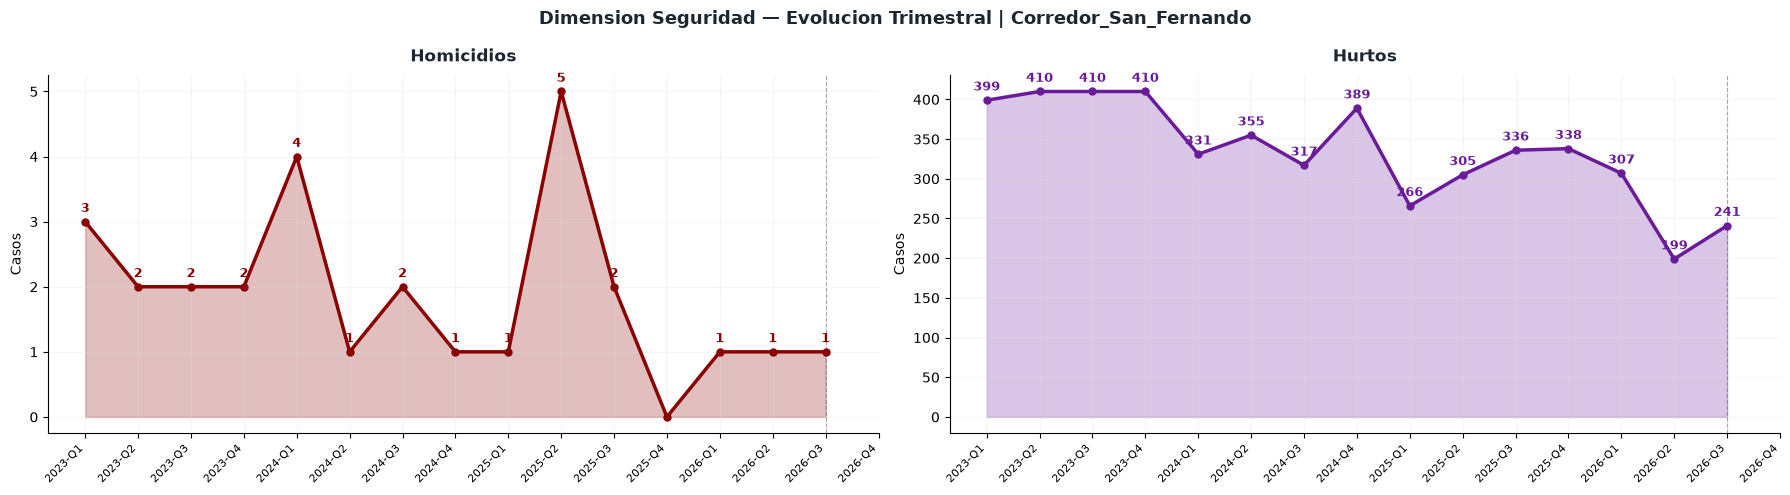

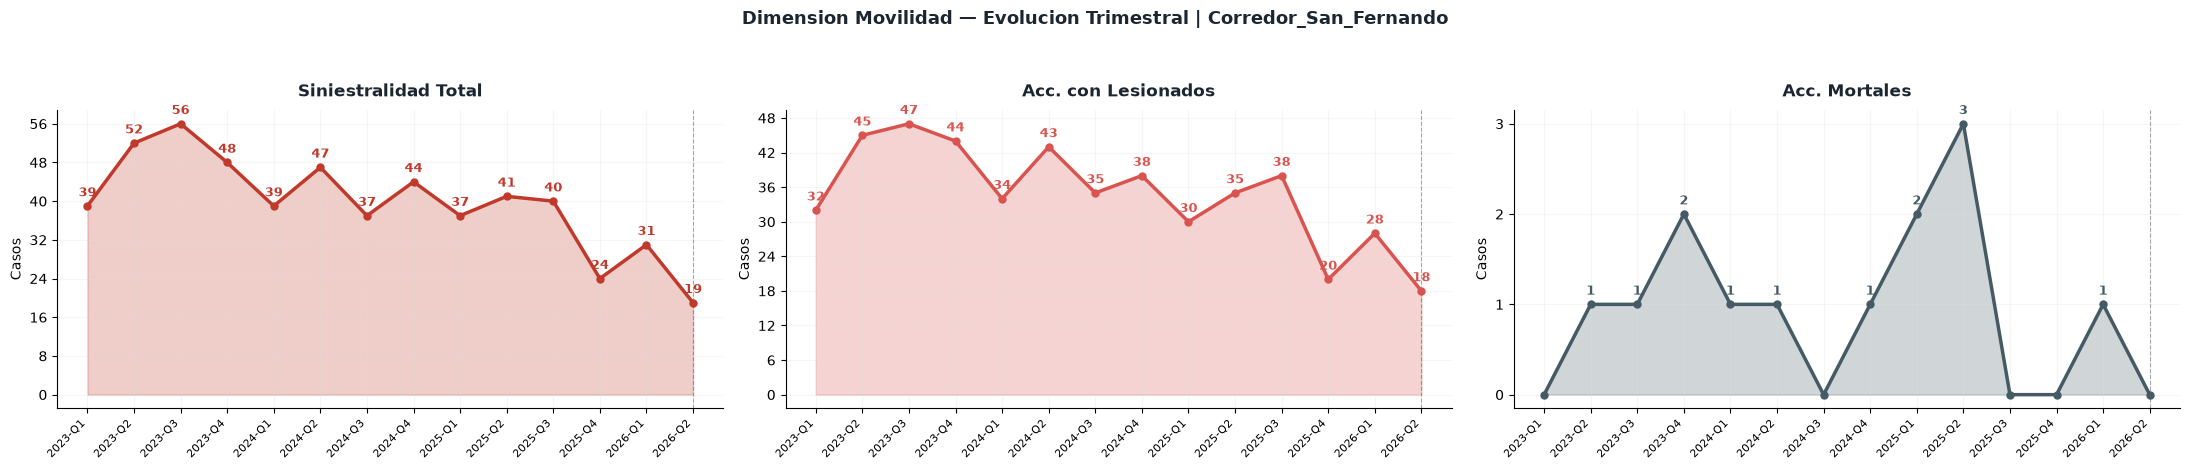

@@SUB graficas_trimestrales | seg + mov guardadas


In [13]:
# EVOLUCION TRIMESTRAL — Seguridad y Movilidad (conteos REALES de corr_trim). Sin rótulo 'Parcial'.
_per = corr_trim['periodo'].values; _x = list(range(len(_per)))
def _linefill(ax,col,titulo,color,df=corr_trim):
    vals=df[col].values.astype(float); valid=~pd.isna(vals)
    import numpy as _np
    ax.fill_between(_x,_np.where(valid,vals,_np.nan),alpha=0.25,color=color)
    ax.plot(_x,_np.where(valid,vals,_np.nan),color=color,linewidth=2.5,marker='o',markersize=5,zorder=3)
    for i,v in enumerate(vals):
        if pd.notna(v) and v>0:
            ax.annotate(str(int(v)),(i,v),textcoords='offset points',xytext=(0,7),ha='center',fontsize=9,fontweight='bold',color=color)
    _ult=max((i for i,v in enumerate(vals) if pd.notna(v)),default=0)
    ax.axvline(_ult,color=OKI_GRIS,linewidth=0.8,linestyle='--',alpha=0.4)
    ax.set_xticks(_x); ax.set_xticklabels(_per,rotation=45,ha='right',fontsize=8)
    ax.set_title(titulo,fontweight='bold',pad=10,color='#1B2631'); ax.set_ylabel('Casos')
    ax.yaxis.set_major_locator(plt.MaxNLocator(integer=True)); ax.set_facecolor(BG)
fig,axes=plt.subplots(1,2,figsize=(18,5),facecolor=BG)
fig.suptitle(f'Dimension Seguridad — Evolucion Trimestral | {ZONA_SLUG}',fontsize=13,fontweight='bold',color='#1B2631')
_linefill(axes[0],'homicidios','Homicidios',ITT['homicidios']); _linefill(axes[1],'hurtos','Hurtos',ITT['hurtos'])
plt.tight_layout(); plt.savefig(_OUT_IMG/f'fig_seguridad_trim_{ZONA_SLUG}.png',dpi=DPI,bbox_inches='tight',facecolor=BG); plt.show()

_ctm=corr_trim.copy().reset_index(drop=True)
_mc=['siniestralidad','lesionados','mortales']
_ctm=_ctm[~((_ctm['año']==2026)&_ctm[_mc].isna().all(axis=1))].reset_index(drop=True)
_perm=_ctm['periodo'].tolist(); _xm=list(range(len(_perm)))
def _linefill_m(ax,col,titulo,color):
    import numpy as _np
    vals=_ctm[col].values.astype(float); valid=~pd.isna(vals)
    ax.fill_between(_xm,_np.where(valid,vals,_np.nan),alpha=0.25,color=color)
    ax.plot(_xm,_np.where(valid,vals,_np.nan),color=color,linewidth=2.5,marker='o',markersize=5,zorder=3)
    for i,v in enumerate(vals):
        if pd.notna(v) and v>0:
            ax.annotate(str(int(v)),(i,v),textcoords='offset points',xytext=(0,7),ha='center',fontsize=9,fontweight='bold',color=color)
    _u=max((i for i,v in enumerate(vals) if pd.notna(v)),default=0)
    ax.axvline(_u,color=OKI_GRIS,linewidth=0.8,linestyle='--',alpha=0.4)
    ax.set_xticks(_xm); ax.set_xticklabels(_perm,rotation=45,ha='right',fontsize=8)
    ax.set_title(titulo,fontweight='bold',pad=10,color='#1B2631'); ax.set_ylabel('Casos')
    ax.yaxis.set_major_locator(plt.MaxNLocator(integer=True)); ax.set_facecolor(BG)
fig,axes=plt.subplots(1,3,figsize=(22,5),facecolor=BG)
fig.suptitle(f'Dimension Movilidad — Evolucion Trimestral | {ZONA_SLUG}',fontsize=13,fontweight='bold',color='#1B2631')
_linefill_m(axes[0],'siniestralidad','Siniestralidad Total',ITT['siniestralidad'])
_linefill_m(axes[1],'lesionados','Acc. con Lesionados',ITT['lesionados'])
_linefill_m(axes[2],'mortales','Acc. Mortales',ITT['mortales'])
plt.tight_layout(rect=[0,0.05,1,0.93]); plt.savefig(_OUT_IMG/f'fig_movilidad_trim_{ZONA_SLUG}.png',dpi=DPI,bbox_inches='tight',facecolor=BG); plt.show()
print('@@SUB graficas_trimestrales | seg + mov guardadas')

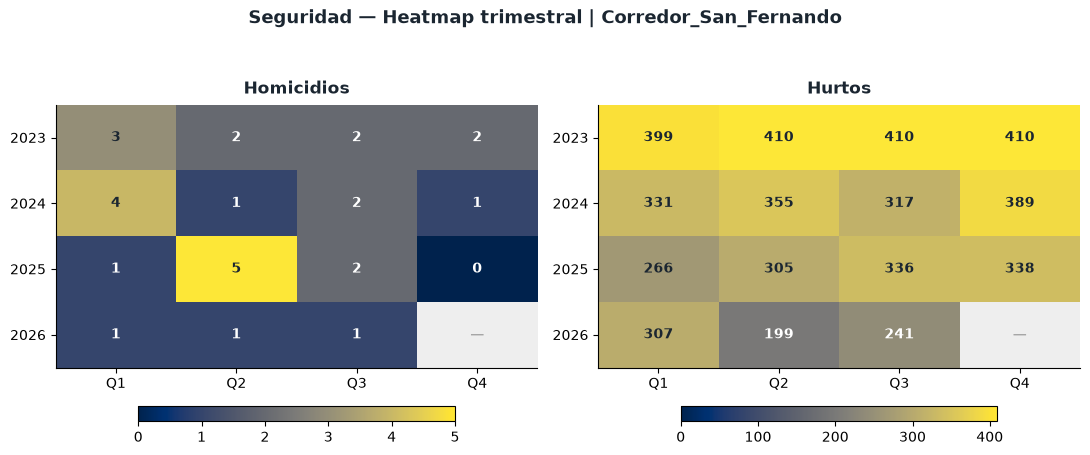

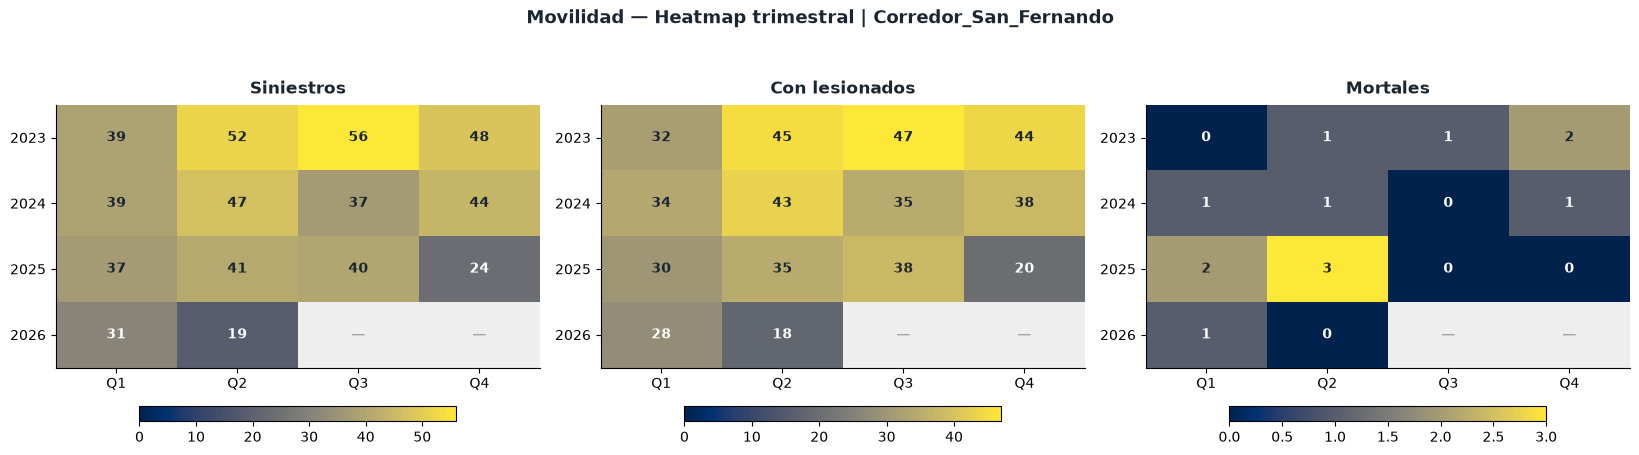

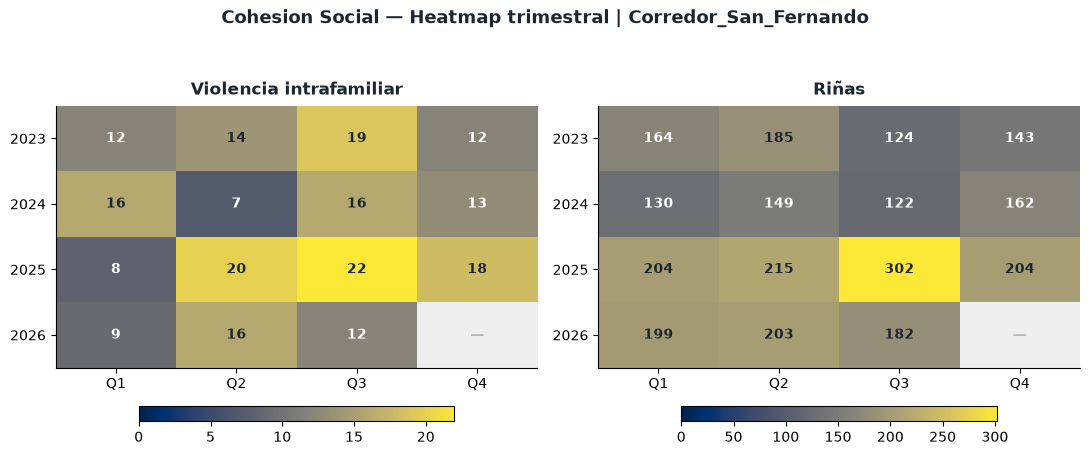

@@SUB heatmaps | fig_seguridad_heatmap_Corredor_San_Fernando.png | fig_movilidad_heatmap_Corredor_San_Fernando.png | fig_cohesion_heatmap_Corredor_San_Fernando.png


In [14]:
# HEATMAPS TRIMESTRALES por dimension (conteos REALES de corr_trim; '—' = trimestre sin dato).
_cmap = plt.get_cmap('cividis').copy(); _cmap.set_bad('#EEEEEE')
def _heatmap_dim(cols_tit, suptitulo, fname):
    n = len(cols_tit)
    fig, axes = plt.subplots(1, n, figsize=(5.5*n, 4.6), facecolor=BG)
    axes = np.atleast_1d(axes)
    for ax, (col, tit) in zip(axes, cols_tit):
        M = corr_trim.set_index(['año','trimestre'])[col].unstack('trimestre').reindex(index=ANIOS, columns=[1,2,3,4])
        arr = M.values.astype(float)
        vmax = max(np.nanmax(arr) if np.isfinite(arr).any() else 1.0, 1.0)
        im = ax.imshow(np.ma.masked_invalid(arr), cmap=_cmap, aspect='auto', vmin=0, vmax=vmax)
        for i in range(arr.shape[0]):
            for j in range(arr.shape[1]):
                v = arr[i, j]
                if np.isnan(v):
                    ax.text(j, i, '—', ha='center', va='center', color='#888888', fontsize=10)
                else:
                    ax.text(j, i, f'{int(v)}', ha='center', va='center', fontsize=10, fontweight='bold',
                            color='white' if v < 0.6*vmax else '#1B2631')
        ax.set_xticks(range(4)); ax.set_xticklabels(['Q1','Q2','Q3','Q4'])
        ax.set_yticks(range(len(ANIOS))); ax.set_yticklabels([str(a) for a in ANIOS])
        ax.set_title(tit, fontweight='bold', pad=8, color='#1B2631'); ax.grid(False)
        plt.colorbar(im, ax=ax, orientation='horizontal', pad=0.12, fraction=0.05)
    fig.suptitle(suptitulo, fontsize=13, fontweight='bold', color='#1B2631')
    plt.tight_layout(rect=[0, 0, 1, 0.93])
    plt.savefig(OUT_IMG/fname, dpi=DPI, bbox_inches='tight', facecolor=BG); plt.show()
    return fname
_hm = [
    _heatmap_dim([('homicidios','Homicidios'),('hurtos','Hurtos')],
                 f'Seguridad — Heatmap trimestral | {ZONA_SLUG}', f'fig_seguridad_heatmap_{ZONA_SLUG}.png'),
    _heatmap_dim([('siniestralidad','Siniestros'),('lesionados','Con lesionados'),('mortales','Mortales')],
                 f'Movilidad — Heatmap trimestral | {ZONA_SLUG}', f'fig_movilidad_heatmap_{ZONA_SLUG}.png'),
    _heatmap_dim([('vif','Violencia intrafamiliar'),('rinas','Riñas')],
                 f'Cohesion Social — Heatmap trimestral | {ZONA_SLUG}', f'fig_cohesion_heatmap_{ZONA_SLUG}.png'),
]
print('@@SUB heatmaps |', ' | '.join(_hm))

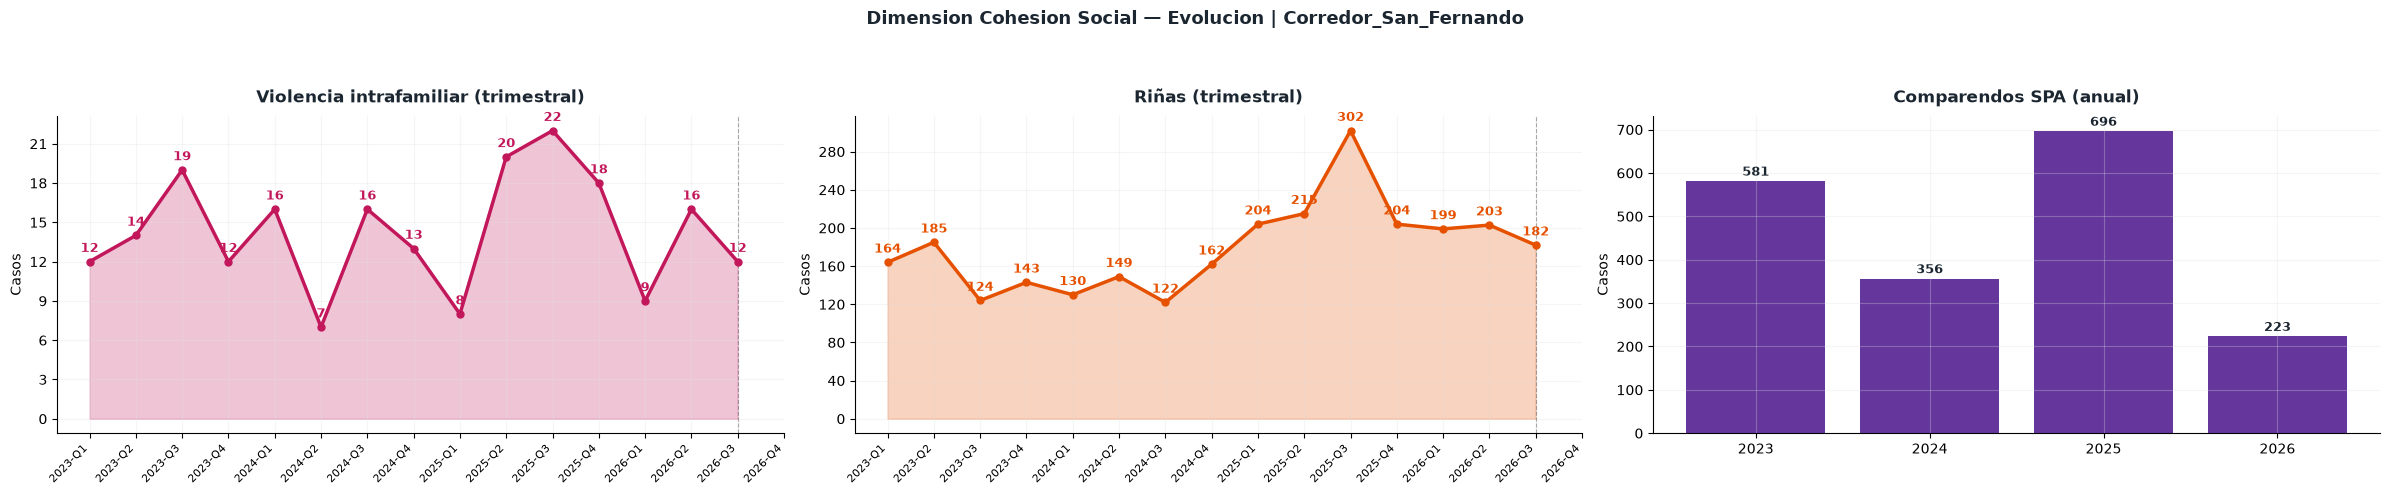

@@SUB cohesion | fig_cohesion_evol guardada


In [15]:
# COHESION SOCIAL — evolucion trimestral VIF y riñas + SPA anual (conteos REALES).
fig, axes = plt.subplots(1, 3, figsize=(24, 5), facecolor=BG)
fig.suptitle(f'Dimension Cohesion Social — Evolucion | {ZONA_SLUG}', fontsize=13, fontweight='bold', color='#1B2631')
_linefill(axes[0], 'vif', 'Violencia intrafamiliar (trimestral)', ITT['vif'])
_linefill(axes[1], 'rinas', 'Riñas (trimestral)', ITT['rinas'])
_ax = axes[2]
_v = base['spa'].astype(float).values
_b = _ax.bar([str(a) for a in ANIOS], _v, color=ITT['spa'], alpha=0.85)
for r, v in zip(_b, _v):
    _ax.annotate(f'{int(v)}', (r.get_x()+r.get_width()/2, v), textcoords='offset points', xytext=(0, 4),
                 ha='center', fontsize=9, fontweight='bold', color='#1B2631')
_ax.set_title('Comparendos SPA (anual)', fontweight='bold', pad=10, color='#1B2631')
_ax.set_ylabel('Casos'); _ax.set_facecolor(BG)
plt.tight_layout(rect=[0, 0, 1, 0.92])
plt.savefig(OUT_IMG/f'fig_cohesion_evol_{ZONA_SLUG}.png', dpi=DPI, bbox_inches='tight', facecolor=BG); plt.show()
print('@@SUB cohesion | fig_cohesion_evol guardada')

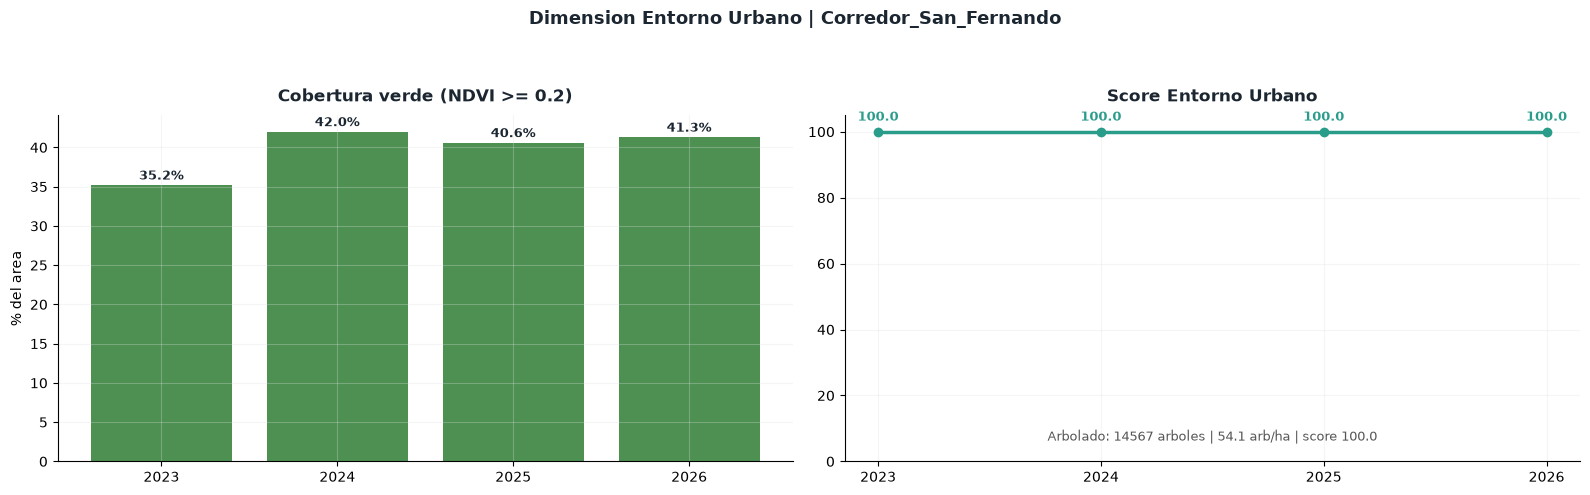

@@SUB entorno_fig | fig_entorno guardada


In [16]:
# ENTORNO URBANO — cobertura verde NDVI y score de entorno por año.
_pv = [ndvi_stats.get(a, {}).get('pct_verde', np.nan) for a in ANIOS]
fig, axes = plt.subplots(1, 2, figsize=(16, 5), facecolor=BG)
fig.suptitle(f'Dimension Entorno Urbano | {ZONA_SLUG}', fontsize=13, fontweight='bold', color='#1B2631')
ax = axes[0]
_b = ax.bar([str(a) for a in ANIOS], [0 if pd.isna(v) else v for v in _pv], color=ITT['arboreo'], alpha=0.85)
for r, v in zip(_b, _pv):
    if not pd.isna(v):
        ax.annotate(f'{v:.1f}%', (r.get_x()+r.get_width()/2, v), textcoords='offset points', xytext=(0, 4),
                    ha='center', fontsize=9, fontweight='bold', color='#1B2631')
ax.set_title(f'Cobertura verde (NDVI >= {NDVI_UMBRAL})', fontweight='bold', pad=10, color='#1B2631')
ax.set_ylabel('% del area'); ax.set_facecolor(BG)
ax = axes[1]
_s = base['score_entorno_u'].astype(float).values
ax.plot([str(a) for a in ANIOS], _s, color=ITT['caminable'], linewidth=2.5, marker='o', markersize=6)
for i, v in enumerate(_s):
    if not pd.isna(v):
        ax.annotate(f'{v:.1f}', (i, v), textcoords='offset points', xytext=(0, 8), ha='center',
                    fontsize=9, fontweight='bold', color=ITT['caminable'])
ax.set_ylim(0, 105); ax.set_title('Score Entorno Urbano', fontweight='bold', pad=10, color='#1B2631')
ax.set_facecolor(BG)
ax.text(0.5, 0.06, f'Arbolado: {ARBOLES_N} arboles | {dens} arb/ha | score {score_arb}',
        transform=ax.transAxes, ha='center', fontsize=9, color='#555555')
plt.tight_layout(rect=[0, 0, 1, 0.92])
plt.savefig(OUT_IMG/f'fig_entorno_{ZONA_SLUG}.png', dpi=DPI, bbox_inches='tight', facecolor=BG); plt.show()
print('@@SUB entorno_fig | fig_entorno guardada')

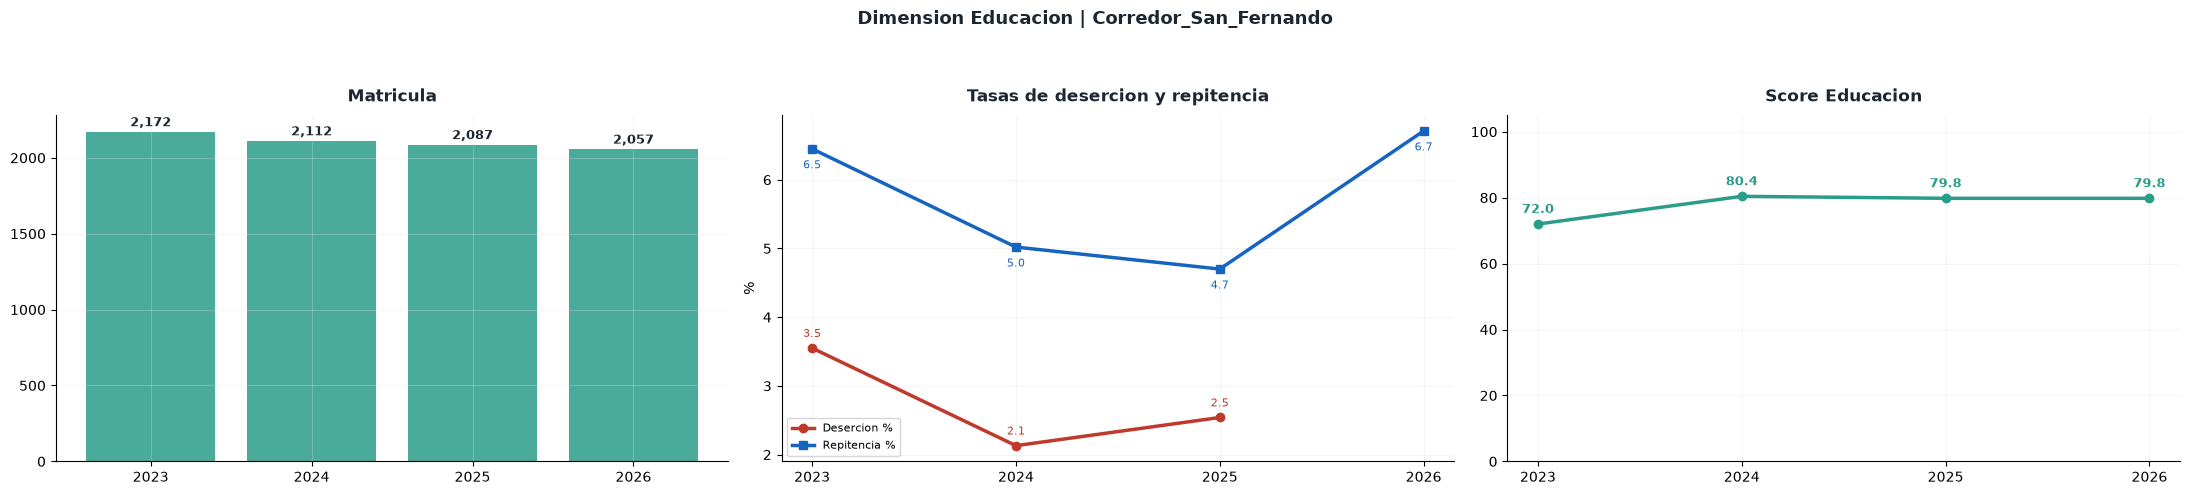

@@SUB educacion_fig | fig_educacion guardada


In [17]:
# EDUCACION — matricula, tasas de desercion/repitencia y score (consolidado de la zona).
_m  = [mat.get(a) for a in ANIOS]
_td = [round(des[a]/mat[a]*100, 2) if (des.get(a) is not None and mat.get(a)) else np.nan for a in ANIOS]
_tr = [round(rep[a]/mat[a]*100, 2) if (rep.get(a) is not None and mat.get(a)) else np.nan for a in ANIOS]
_xa = [str(a) for a in ANIOS]
fig, axes = plt.subplots(1, 3, figsize=(22, 5), facecolor=BG)
fig.suptitle(f'Dimension Educacion | {ZONA_SLUG}', fontsize=13, fontweight='bold', color='#1B2631')
ax = axes[0]
_b = ax.bar(_xa, [v or 0 for v in _m], color=ITT['educacion'], alpha=0.85)
for r, v in zip(_b, _m):
    if v:
        ax.annotate(f'{int(v):,}', (r.get_x()+r.get_width()/2, v), textcoords='offset points', xytext=(0, 4),
                    ha='center', fontsize=9, fontweight='bold', color='#1B2631')
ax.set_title('Matricula', fontweight='bold', pad=10, color='#1B2631'); ax.set_facecolor(BG)
ax = axes[1]
ax.plot(_xa, _td, color=ITT['siniestralidad'], linewidth=2.5, marker='o', label='Desercion %')
ax.plot(_xa, _tr, color=ITT['establecimientos'], linewidth=2.5, marker='s', label='Repitencia %')
for i, (d, r) in enumerate(zip(_td, _tr)):
    if not pd.isna(d): ax.annotate(f'{d:.1f}', (i, d), textcoords='offset points', xytext=(0, 8), ha='center', fontsize=8, color=ITT['siniestralidad'])
    if not pd.isna(r): ax.annotate(f'{r:.1f}', (i, r), textcoords='offset points', xytext=(0, -14), ha='center', fontsize=8, color=ITT['establecimientos'])
ax.set_title('Tasas de desercion y repitencia', fontweight='bold', pad=10, color='#1B2631')
ax.set_ylabel('%'); ax.legend(fontsize=8); ax.set_facecolor(BG)
ax = axes[2]
_se = base['score_educ_des'].astype(float).values
ax.plot(_xa, _se, color=ITT['caminable'], linewidth=2.5, marker='o')
for i, v in enumerate(_se):
    if not pd.isna(v): ax.annotate(f'{v:.1f}', (i, v), textcoords='offset points', xytext=(0, 8), ha='center', fontsize=9, fontweight='bold', color=ITT['caminable'])
ax.set_ylim(0, 105); ax.set_title('Score Educacion', fontweight='bold', pad=10, color='#1B2631'); ax.set_facecolor(BG)
plt.tight_layout(rect=[0, 0, 1, 0.92])
plt.savefig(OUT_IMG/f'fig_educacion_{ZONA_SLUG}.png', dpi=DPI, bbox_inches='tight', facecolor=BG); plt.show()
print('@@SUB educacion_fig | fig_educacion guardada')

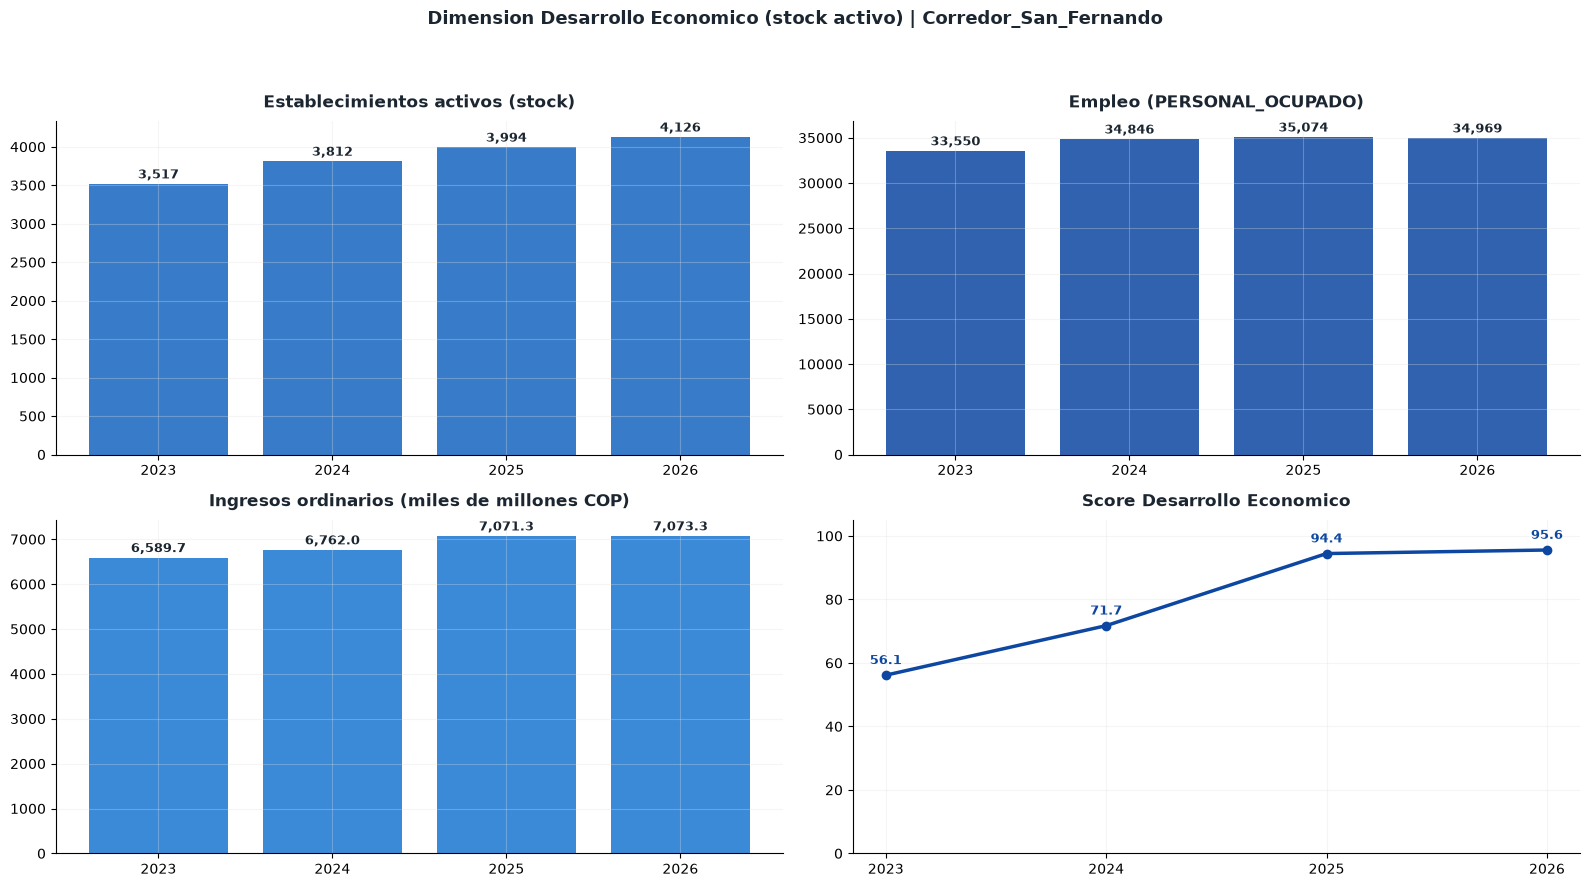

@@SUB de_fig | fig_de_stock guardada


In [18]:
# DESARROLLO ECONOMICO — stock activo: establecimientos, empleo, ingresos y score.
_xd = [str(int(a)) for a in dfs['año']]
_series = [
    (dfs['est'].values,       'Establecimientos activos (stock)',          ITT['establecimientos'], '{:,.0f}'),
    (dfs['emp'].values,       'Empleo (PERSONAL_OCUPADO)',                 ITT['empleo'],    '{:,.0f}'),
    (dfs['ing'].values/1e9,   'Ingresos ordinarios (miles de millones COP)', ITT['ingresos'], '{:,.1f}'),
]
fig, axes = plt.subplots(2, 2, figsize=(16, 9), facecolor=BG)
fig.suptitle(f'Dimension Desarrollo Economico (stock activo) | {ZONA_SLUG}', fontsize=13, fontweight='bold', color='#1B2631')
for ax, (vals, tit, color, fmt) in zip(axes.flat, _series):
    _vp = np.array([0.0 if pd.isna(v) else v for v in vals], dtype=float)
    _b = ax.bar(_xd, _vp, color=color, alpha=0.85)
    for r, v in zip(_b, vals):
        if pd.isna(v): continue
        ax.annotate(fmt.format(v), (r.get_x()+r.get_width()/2, v), textcoords='offset points', xytext=(0, 4),
                    ha='center', fontsize=9, fontweight='bold', color='#1B2631')
    _t = tit + (' — s/d' if all(pd.isna(v) for v in vals) else '')
    ax.set_title(_t, fontweight='bold', pad=10, color='#1B2631'); ax.set_facecolor(BG)
ax = axes[1, 1]
_sd = base['score_des_eco'].astype(float).values
ax.plot([str(a) for a in ANIOS], _sd, color=ITT['de'], linewidth=2.5, marker='o')
for i, v in enumerate(_sd):
    if not pd.isna(v): ax.annotate(f'{v:.1f}', (i, v), textcoords='offset points', xytext=(0, 8), ha='center', fontsize=9, fontweight='bold', color=ITT['de'])
ax.set_ylim(0, 105); ax.set_title('Score Desarrollo Economico', fontweight='bold', pad=10, color='#1B2631'); ax.set_facecolor(BG)
plt.tight_layout(rect=[0, 0, 1, 0.94])
plt.savefig(OUT_IMG/f'fig_de_stock_{ZONA_SLUG}.png', dpi=DPI, bbox_inches='tight', facecolor=BG); plt.show()
print('@@SUB de_fig | fig_de_stock guardada')

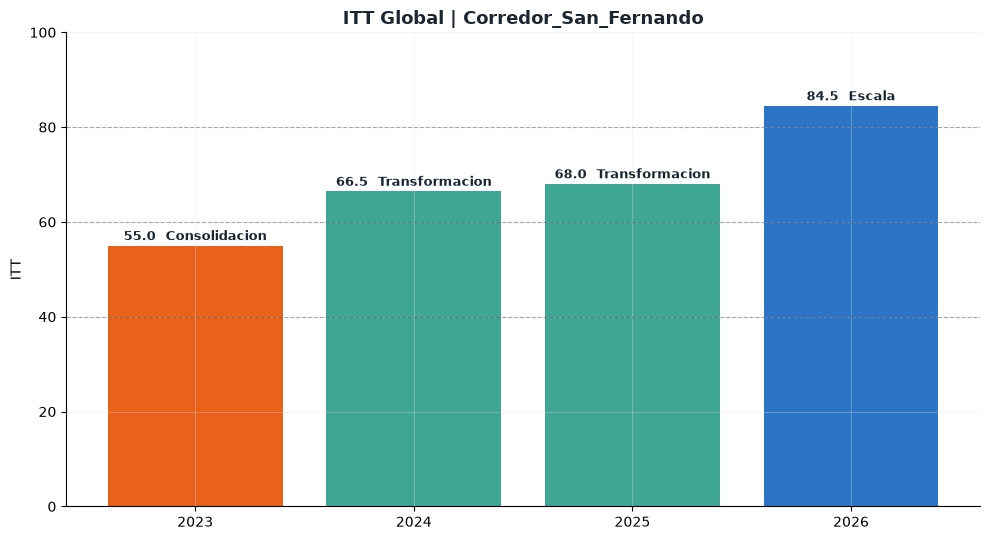

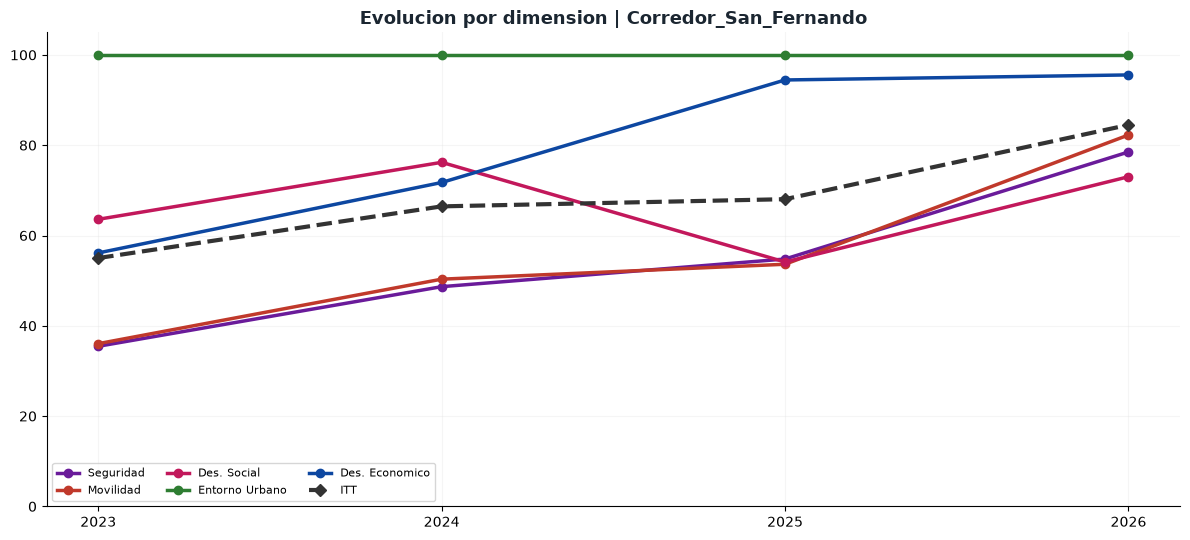

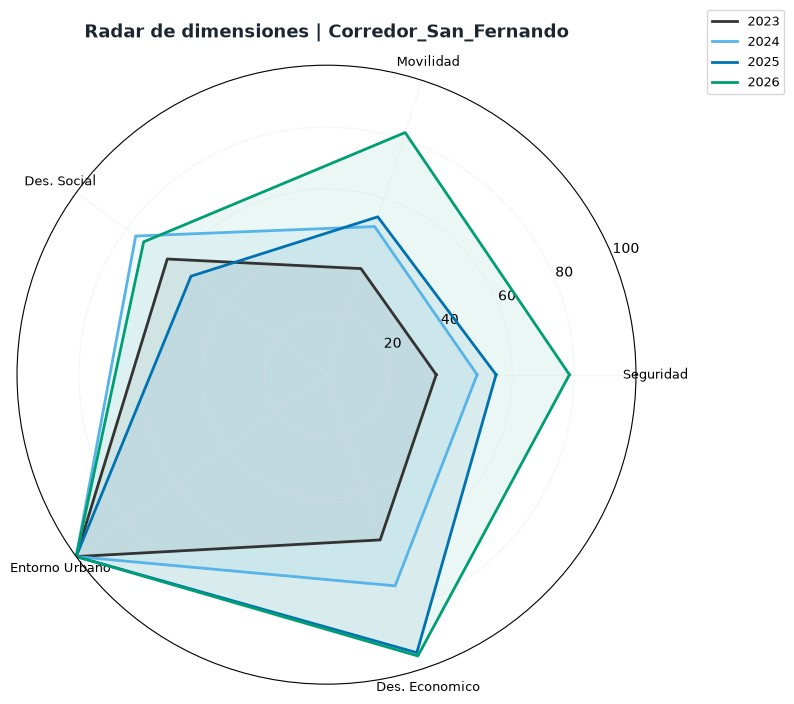

@@SUB transversales | fig_itt_global, fig_itt_dimensiones, fig_itt_radar guardadas


In [19]:
# TRANSVERSALES — ITT global por año, evolucion de las 5 dimensiones y radar.
_xa = [str(a) for a in ANIOS]
_dims = [('score_seguridad','Seguridad',DIM_COLOR['Seguridad']), ('score_movilidad','Movilidad',DIM_COLOR['Movilidad']),
         ('score_des_social','Des. Social',DIM_COLOR['DesSocial']), ('score_entorno_u','Entorno Urbano',DIM_COLOR['EntornoU']),
         ('score_des_eco','Des. Economico',DIM_COLOR['DesEco'])]
# 1) ITT global
fig, ax = plt.subplots(figsize=(10, 5.5), facecolor=BG)
_itt = base['ITT'].astype(float).values; _niv = base['nivel'].tolist()
_b = ax.bar(_xa, _itt, color=[NIVEL_COLORS.get(n, OKI_GRIS) for n in _niv], alpha=0.9)
for r, v, n in zip(_b, _itt, _niv):
    ax.annotate(f'{v:.1f}  {n}', (r.get_x()+r.get_width()/2, v), textcoords='offset points', xytext=(0, 4),
                ha='center', fontsize=9, fontweight='bold', color='#1B2631')
for t in (40, 60, 80): ax.axhline(t, color=OKI_GRIS, linestyle='--', linewidth=0.8, alpha=0.4)
ax.set_ylim(0, 100); ax.set_ylabel('ITT')
ax.set_title(f'ITT Global | {ZONA_SLUG}', fontsize=13, fontweight='bold', color='#1B2631'); ax.set_facecolor(BG)
plt.tight_layout(); plt.savefig(OUT_IMG/f'fig_itt_global_{ZONA_SLUG}.png', dpi=DPI, bbox_inches='tight', facecolor=BG); plt.show()
# 2) evolucion por dimension
fig, ax = plt.subplots(figsize=(12, 5.5), facecolor=BG)
for col, lab, color in _dims:
    ax.plot(_xa, base[col].astype(float).values, color=color, linewidth=2.5, marker='o', label=lab)
ax.plot(_xa, _itt, color=OKI_GRIS, linewidth=3, linestyle='--', marker='D', label='ITT')
ax.set_ylim(0, 105); ax.legend(fontsize=8, ncol=3)
ax.set_title(f'Evolucion por dimension | {ZONA_SLUG}', fontsize=13, fontweight='bold', color='#1B2631'); ax.set_facecolor(BG)
plt.tight_layout(); plt.savefig(OUT_IMG/f'fig_itt_dimensiones_{ZONA_SLUG}.png', dpi=DPI, bbox_inches='tight', facecolor=BG); plt.show()
# 3) radar
fig = plt.figure(figsize=(8, 8), facecolor=BG); ax = fig.add_subplot(111, projection='polar')
_lab = [d[1] for d in _dims]
_ang = np.linspace(0, 2*np.pi, len(_lab), endpoint=False).tolist(); _ang += _ang[:1]
for a, color in zip(ANIOS, [OKI_GRIS, OKI_AZUL_C, OKI_AZUL, OKI_VERDE]):
    vals = [float(base.loc[base['año']==a, d[0]].iloc[0]) for d in _dims]; vals += vals[:1]
    ax.plot(_ang, vals, color=color, linewidth=2, label=str(a)); ax.fill(_ang, vals, color=color, alpha=0.08)
ax.set_xticks(_ang[:-1]); ax.set_xticklabels(_lab, fontsize=9); ax.set_ylim(0, 100)
ax.legend(loc='upper right', bbox_to_anchor=(1.25, 1.1), fontsize=9)
ax.set_title(f'Radar de dimensiones | {ZONA_SLUG}', fontsize=13, fontweight='bold', color='#1B2631', pad=20)
plt.tight_layout(); plt.savefig(OUT_IMG/f'fig_itt_radar_{ZONA_SLUG}.png', dpi=DPI, bbox_inches='tight', facecolor=BG); plt.show()
print('@@SUB transversales | fig_itt_global, fig_itt_dimensiones, fig_itt_radar guardadas')

In [20]:
# MAPA — tiles de Google (Calles activa; Satelite/Hibrido/CartoDB alternos). Capas de datos
# presentes pero DESACTIVADAS. Los puntos salen del extractor central (GeoDataFrames recortados).
import folium
from folium.plugins import HeatMap
poly_wgs = _poly_wgs   # definido en la celda de extraccion (ext.poly_wgs en local; leido del disco en Colab)
_c = poly_wgs.geometry.union_all().centroid
m = folium.Map(location=[_c.y,_c.x], zoom_start=16, tiles=None, control_scale=True)
folium.TileLayer(tiles='https://mt1.google.com/vt/lyrs=m&x={x}&y={y}&z={z}',attr='Google',name='Google Calles',overlay=False,control=True,show=True).add_to(m)
folium.TileLayer(tiles='https://mt1.google.com/vt/lyrs=s&x={x}&y={y}&z={z}',attr='Google',name='Google Satelite',overlay=False,control=True,show=False).add_to(m)
folium.TileLayer(tiles='https://mt1.google.com/vt/lyrs=y&x={x}&y={y}&z={z}',attr='Google',name='Google Hibrido',overlay=False,control=True,show=False).add_to(m)
folium.TileLayer('CartoDB positron',name='CartoDB (claro)',overlay=False,control=True,show=False).add_to(m)
folium.GeoJson(poly_wgs.__geo_interface__,name=f'Area {ZONA_SLUG}'+(' (buffer 100 m)' if TIENE_ESPEJO else ''),
    style_function=lambda x:{'fillColor':'#2E7D32','color':'#1B4F8A','weight':2.5,'fillOpacity':0.08}).add_to(m)
def _capa_pts(gdf,nombre,color,fill,radio=4,show=False):
    fg=folium.FeatureGroup(name=nombre,show=show)
    if gdf is not None and len(gdf):
        for _,r in gdf.iterrows():
            try: lon,lat=r.geometry.x,r.geometry.y
            except Exception: continue
            folium.CircleMarker([lat,lon],radius=radio,color=color,fill=True,fill_color=fill,fill_opacity=0.65).add_to(fg)
    fg.add_to(m); return fg
_capa_pts(g_hur,'Hurtos (puntos)','#1565C0','#1E88E5')
_capa_pts(g_sin,'Siniestros viales','#E65100','#FB8C00',radio=5)
_capa_pts(g_rin,'Rinas (comparendos)','#6A1B9A','#AB47BC')
_capa_pts(g_spa,'Comparendos SPA','#4A148C','#7E57C2')
# VIF SOLO como heatmap (nunca puntos: privacidad de victimas)
_hv=[[r.geometry.y,r.geometry.x] for _,r in g_vif.iterrows()] if (g_vif is not None and len(g_vif)) else []
if _hv: HeatMap(_hv,name='VIF (heatmap)',min_opacity=0.3,radius=14,blur=10,show=False).add_to(m)
_capa_pts(g_hom,'Homicidios','#B71C1C','#E53935',radio=6)
_heat=[[r.geometry.y,r.geometry.x] for _,r in g_hur.iterrows()] if (g_hur is not None and len(g_hur)) else []
if _heat: HeatMap(_heat,name='Hurtos (heatmap)',min_opacity=0.3,radius=12,blur=8,show=False).add_to(m)
folium.LayerControl(collapsed=False).add_to(m)
_MAP_PATH=_OUT_IMG/f'mapa_analitico_{ZONA_SLUG}.html'; m.save(str(_MAP_PATH))
print('@@SUB mapa | guardado en', _MAP_PATH, '| capa activa: Google Calles; datos apagados')
m

@@SUB mapa | guardado en outputs\mapa_analitico_Corredor_San_Fernando\imagenes\mapa_analitico_Corredor_San_Fernando.html | capa activa: Google Calles; datos apagados


In [21]:
# EXPORT EXCEL — 10 hojas, cifras REALES observadas (no anualizadas).
# Estructura estandar: outputs/mapa_analitico_<Zona>/mapa_analitico_<Zona>_consolidado.xlsx.
# Sin input() (no bloquea): usa RAIZ_SALIDA de la config si se definio, si no el default.
_OUT_ZONA = (Path(RAIZ_SALIDA) / OUT_DIR_NAME) if RAIZ_SALIDA else OUT_ZONA
_OUT_ZONA.mkdir(parents=True, exist_ok=True)
(_OUT_ZONA / 'imagenes').mkdir(parents=True, exist_ok=True)
EXPORT_PATH = str(_OUT_ZONA / f'mapa_analitico_{ZONA_SLUG}_consolidado.xlsx')
df_seg = corr_trim[['año','trimestre','periodo','homicidios','hurtos']].merge(base[['año','score_seguridad']],on='año',how='left')
df_mov = corr_trim[['año','trimestre','periodo','siniestralidad','lesionados','mortales']].merge(base[['año','score_movilidad']],on='año',how='left')
_coh_raw = corr_trim.groupby('año')[['vif','rinas']].sum().reset_index()
df_coh = _coh_raw.merge(base[['año','spa','score_spa','score_cohesion']],on='año',how='left')
df_eu_exp = base[['año','score_entorno_u']].copy()
df_educ_exp = base[['año','score_educ_des']].copy()
df_de_export = base[['año','score_des_eco']].merge(dfs[['año','est','emp','ing']],on='año',how='left')
df_trim_export = corr_trim.copy()
df_itt_anual = base[['año','score_seguridad','score_movilidad','score_des_social','score_entorno_u','score_des_eco','ITT','nivel']].copy()
df_itt_trim = corr_trim[['año','trimestre','periodo']].copy()
df_de_trim_2026 = corr_trim[corr_trim['año']==2026][['periodo']].copy()
sheets={'ITT_Resumen':df_itt_anual,'ITT_Trimestral':df_itt_trim,'Seguridad':df_seg,'Movilidad':df_mov,
        'Cohesion_Social':df_coh,'Entorno_Urbano':df_eu_exp,'Educacion':df_educ_exp,
        'Desarrollo_Economico':df_de_export,'DesEco_Trim_2026':df_de_trim_2026,'Indicadores_Trimestrales':df_trim_export}
with pd.ExcelWriter(EXPORT_PATH, engine='openpyxl') as w:
    for nm,dfh in sheets.items():
        (dfh.round(2) if isinstance(dfh,pd.DataFrame) and not dfh.empty else pd.DataFrame({'nota':['sin datos']})).to_excel(w,sheet_name=nm,index=False)
print('@@SUB export_excel | ', EXPORT_PATH)
print('  Hojas:', ' | '.join(sheets.keys()))

@@SUB export_excel |  outputs\mapa_analitico_Corredor_San_Fernando\mapa_analitico_Corredor_San_Fernando_consolidado.xlsx
  Hojas: ITT_Resumen | ITT_Trimestral | Seguridad | Movilidad | Cohesion_Social | Entorno_Urbano | Educacion | Desarrollo_Economico | DesEco_Trim_2026 | Indicadores_Trimestrales
